# Predicción de enfermedad cardiaca con Random Forest

**Inteligencia Artificial I · Actividad 3**
Integrantes: Juan Supelano · pipereinaa · Edwinvas178-bot

Objetivo: entrenar dos clasificadores Random Forest con el *Heart Failure Prediction Dataset*:

| Modelo | Variables | Usuario |
|---|---|---|
| **Rápido** | 7 (edad, sexo, síntomas, presión, colesterol, glucosa) | Cualquier persona |
| **Completo** | 11 (incluye ECG y prueba de esfuerzo) | Personal de salud |

La comparación entre los dos muestra cuánta precisión se pierde al quitar los datos clínicos.

## 1. Carga y exploración de datos

In [1]:
import sys, json, warnings
from datetime import date
sys.path.append('..')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from src.preprocessing import (load_raw, clean, build_pipeline, FEATURES_FULL,
                               FEATURES_QUICK, CATEGORICAL, NUMERIC, TARGET)

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.dpi'] = 110
IMG = '../app/static/img/'   # las figuras se reutilizan en la página "El modelo"

df = load_raw('../data/raw/heart.csv')
print(f'Registros: {df.shape[0]} | Columnas: {df.shape[1]}')
df.head()

Registros: 918 | Columnas: 12


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140.0,289.0,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160.0,180.0,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130.0,283.0,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138.0,214.0,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150.0,195.0,0,Normal,122,N,0.0,Up,0


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       917 non-null    float64
 4   Cholesterol     746 non-null    float64
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(3), int64(4), str(5)
memory usage: 86.2 KB


In [3]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.51,9.43,28.0,47.00,54.0,60.0,77.0
RestingBP,917.0,132.54,18.00,80.0,120.00,130.0,140.0,200.0
Cholesterol,746.0,244.64,59.15,85.0,207.25,237.0,275.0,603.0
FastingBS,918.0,0.23,0.42,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.81,25.46,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.89,1.07,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.55,0.50,0.0,0.00,1.0,1.0,1.0


**Diccionario de variables**

| Variable | Descripción |
|---|---|
| Age | Edad en años |
| Sex | M / F |
| ChestPainType | TA angina típica, ATA angina atípica, NAP dolor no anginoso, ASY asintomático |
| RestingBP | Presión arterial en reposo (mmHg) |
| Cholesterol | Colesterol sérico (mg/dL) |
| FastingBS | 1 si la glucosa en ayunas > 120 mg/dL |
| RestingECG | Normal, ST (anomalía ST-T), LVH (hipertrofia ventricular izquierda) |
| MaxHR | Frecuencia cardiaca máxima alcanzada |
| ExerciseAngina | Angina inducida por ejercicio (Y/N) |
| Oldpeak | Depresión del segmento ST |
| ST_Slope | Pendiente del ST en el pico del ejercicio (Up, Flat, Down) |
| **HeartDisease** | **Variable objetivo: 1 enfermedad cardiaca, 0 normal** |

## 2. Análisis exploratorio (EDA)
### 2.1 Valores nulos y valores imposibles

In [4]:
print('Nulos por columna:')
print(df.isna().sum().to_string())
print()
print('Registros con valor 0:')
print((df[['RestingBP', 'Cholesterol']] == 0).sum().to_string())

Nulos por columna:
Age                 0
Sex                 0
ChestPainType       0
RestingBP           1
Cholesterol       172
FastingBS           0
RestingECG          0
MaxHR               0
ExerciseAngina      0
Oldpeak             0
ST_Slope            0
HeartDisease        0

Registros con valor 0:
RestingBP      0
Cholesterol    0


`Cholesterol` tiene 172 vacíos y `RestingBP` 1. En el CSV original de Kaggle estos faltantes venían como **0**,
un valor fisiológicamente imposible; en nuestra copia ya están como vacíos. La función `clean()` convierte los
ceros a `NaN` por si se usa el archivo original, y el pipeline los imputa con la mediana. Es el mismo mecanismo
que usa la app cuando el usuario responde "No sé".

### 2.2 Variable objetivo

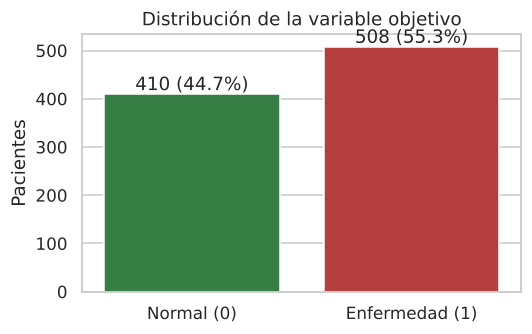

In [5]:
counts = df[TARGET].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3.2))
sns.barplot(x=['Normal (0)', 'Enfermedad (1)'], y=counts.values, ax=ax, palette=['#2b8a3e', '#c92a2a'])
for i, v in enumerate(counts.values):
    ax.text(i, v + 8, f'{v} ({v / len(df):.1%})', ha='center')
ax.set_ylabel('Pacientes'); ax.set_title('Distribución de la variable objetivo')
plt.tight_layout(); plt.show()

Las clases están razonablemente balanceadas, así que *accuracy* es una métrica válida; igual se reportan precision, recall, F1 y ROC-AUC.

### 2.3 Distribución de variables numéricas

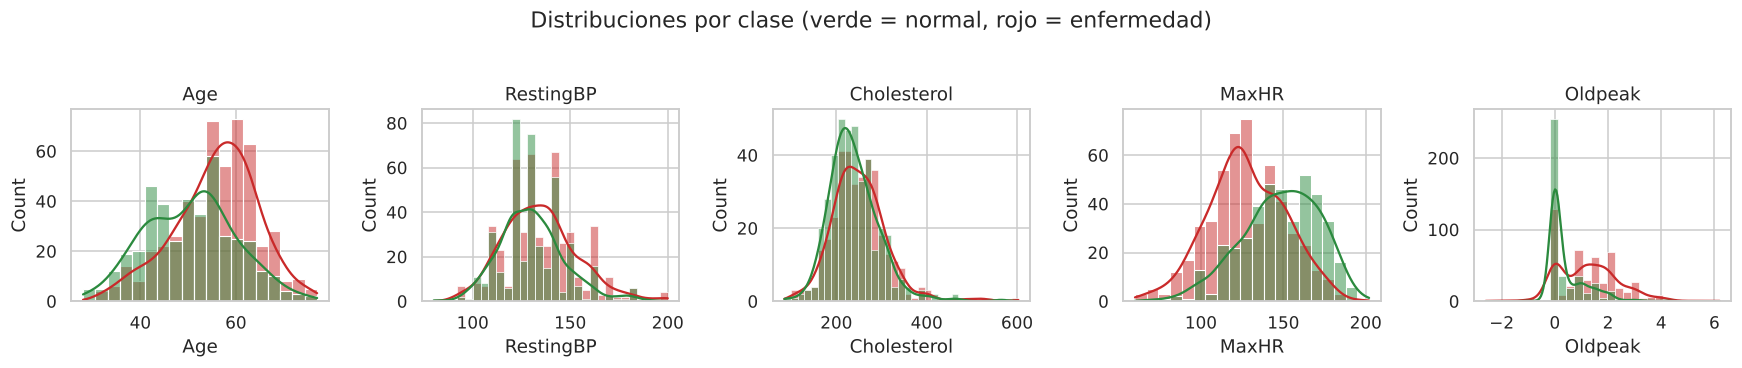

In [6]:
num_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df[df[col] != 0] if col in ('RestingBP', 'Cholesterol') else df,
                 x=col, hue=TARGET, kde=True, ax=ax, palette=['#2b8a3e', '#c92a2a'], legend=False)
    ax.set_title(col)
fig.suptitle('Distribuciones por clase (verde = normal, rojo = enfermedad)', y=1.04)
plt.tight_layout(); plt.show()

### 2.4 Variables categóricas frente a la variable objetivo

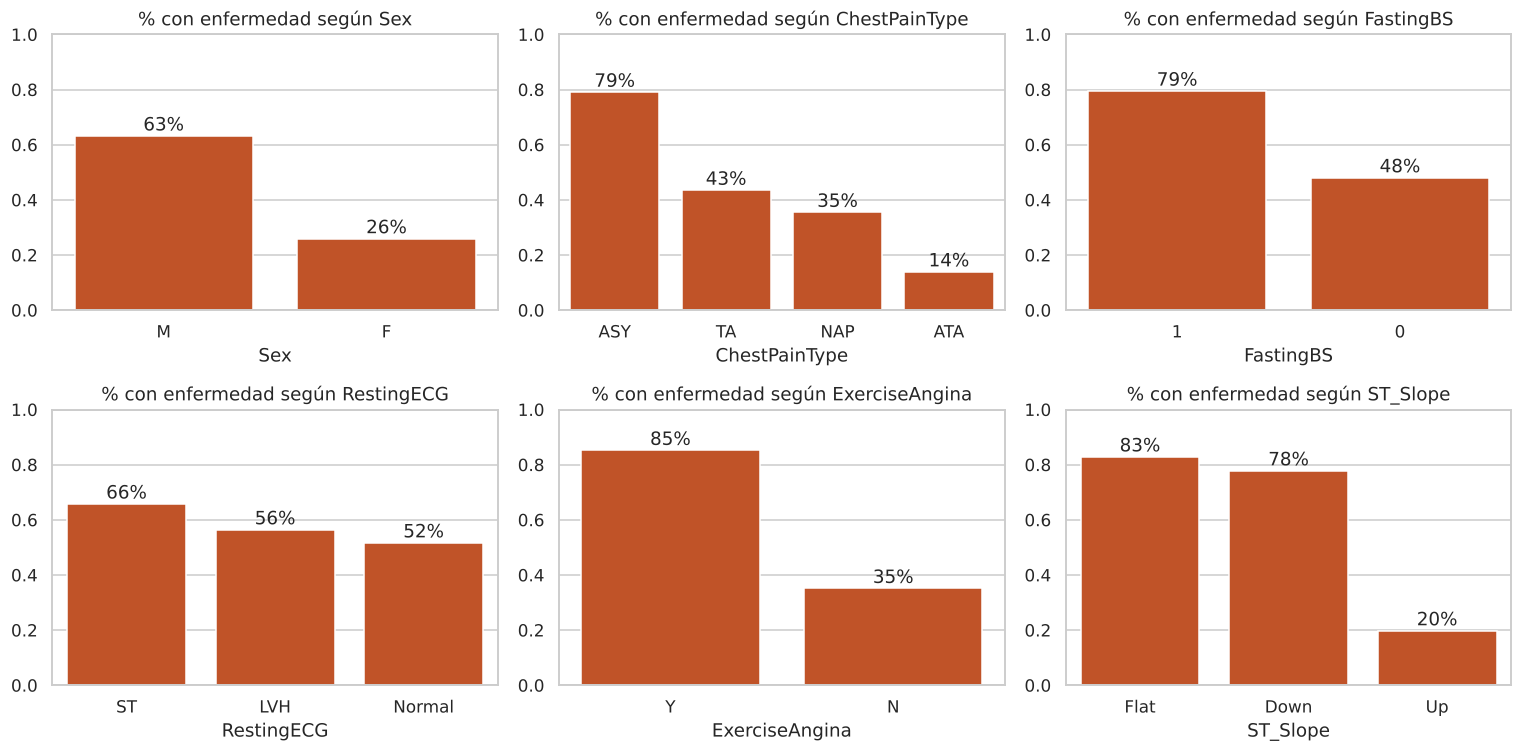

In [7]:
cat_cols = ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    rate = df.groupby(col)[TARGET].mean().sort_values(ascending=False)
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax, color='#d9480f')
    ax.set_ylim(0, 1); ax.set_title(f'% con enfermedad según {col}'); ax.set_ylabel('')
    for i, v in enumerate(rate.values):
        ax.text(i, v + .02, f'{v:.0%}', ha='center')
plt.tight_layout(); plt.show()

Observaciones:
- **ST_Slope plana**, **angina con ejercicio** y **dolor tipo ASY** tienen tasas de enfermedad muy altas.
- Que *asintomático* (ASY) sea el grupo de mayor riesgo parece raro, pero tiene explicación: son pacientes
  que llegaron al estudio por otra razón clínica y no presentaban dolor típico (isquemia silente).
- Los hombres tienen una tasa bastante mayor que las mujeres.

### 2.5 Correlaciones

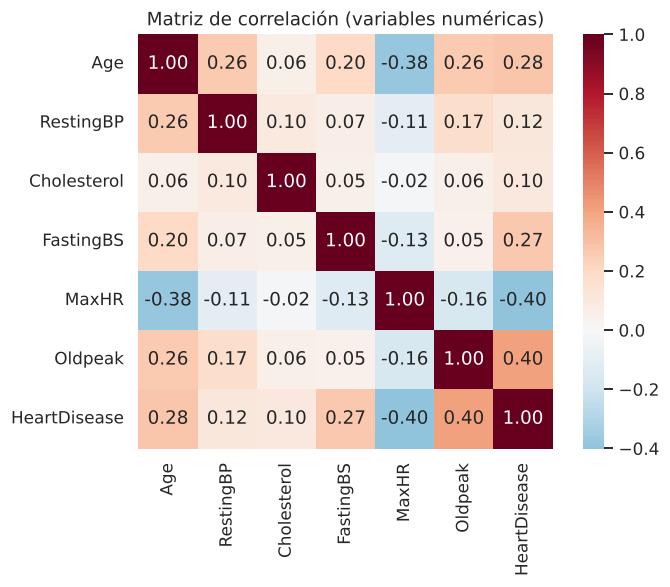

In [8]:
corr = clean(df)[NUMERIC + [TARGET]].corr()
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax, square=True)
ax.set_title('Matriz de correlación (variables numéricas)')
plt.tight_layout(); plt.show()

Ninguna pareja de variables tiene una correlación tan alta como para ser redundante. Oldpeak (+) y MaxHR (−) son las numéricas más relacionadas con la enfermedad.

### 2.6 Outliers

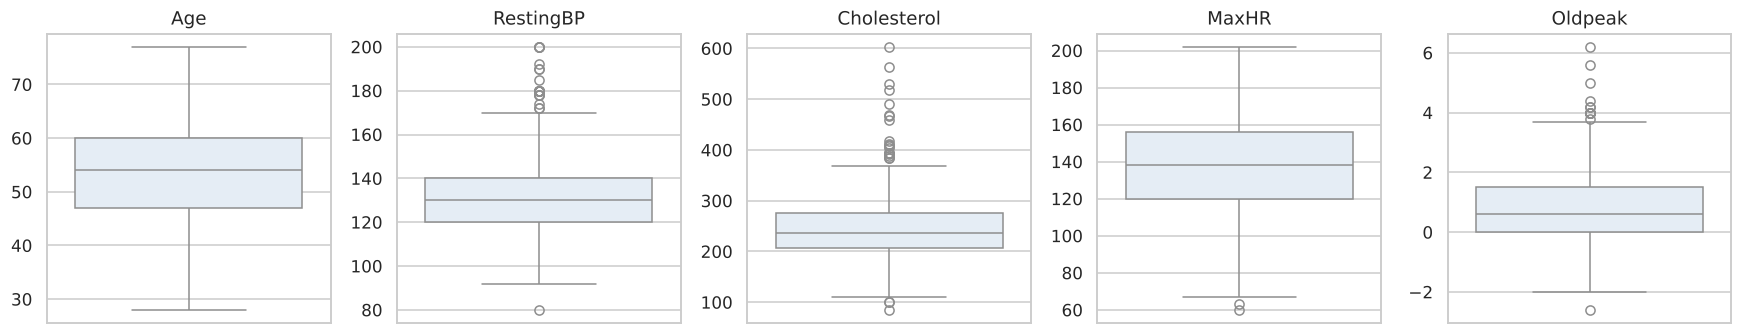

Outliers por criterio IQR:
Age             0
RestingBP      27
Cholesterol    23
MaxHR           2
Oldpeak        16


In [9]:
fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=clean(df)[col], ax=ax, color='#e3edf7')
    ax.set_title(col); ax.set_ylabel('')
plt.tight_layout(); plt.show()

q1, q3 = df[num_cols].quantile([.25, .75]).values
iqr = q3 - q1
outliers = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print('Outliers por criterio IQR:'); print(outliers.to_string())

Los valores extremos (colesterol de 500+, presión de 200) son clínicamente posibles, así que **no se eliminan**.
Random Forest es robusto frente a outliers porque divide por umbrales y no por distancias.